In [ ]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

np.random.seed(42)
X_denso, _ = make_blobs(n_samples=150, centers=[[0, 0]], cluster_std=0.3, random_state=42)
X_sparso = np.random.uniform(low=[15, -4], high=[25, 4], size=(40, 2))
X = np.vstack([X_denso, X_sparso])

In [7]:
k = 5
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X)
distanze_k = np.sort(nn.kneighbors(X)[0][:, k-1])

In [8]:
def conta_rumore(labels):
    return (labels[:150] == -1).sum(), (labels[150:] == -1).sum()

(np.int64(0), np.int64(40))


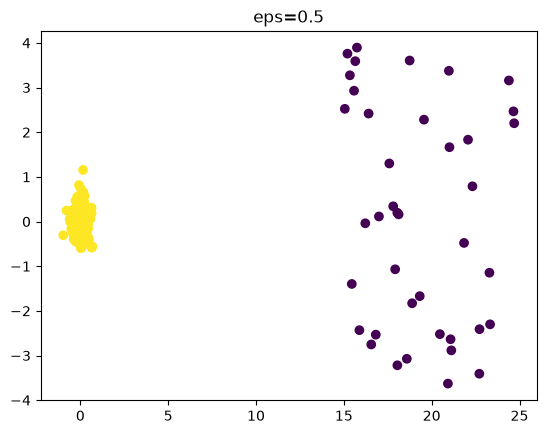

In [9]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
labels = dbscan.fit_predict(X)
print(conta_rumore(labels))
# OUTPUT: (0, 40)

plt.scatter(X[:,0], X[:,1], c=labels, cmap='viridis')
plt.title('eps=0.5')
plt.show()

(np.int64(0), np.int64(3))


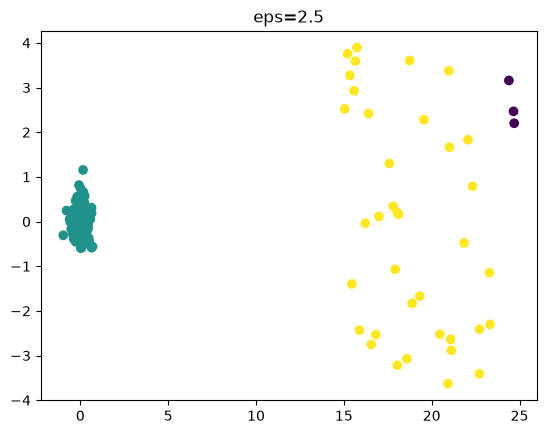

In [11]:
dbscan = DBSCAN(eps=2.5, min_samples=5)
labels = dbscan.fit_predict(X)
print(conta_rumore(labels))
# OUTPUT: (0, 3)

plt.scatter(X[:,0], X[:,1], c=labels, cmap='viridis')
plt.title('eps=2.5')
plt.show()